# ME312 forced-vibration surrogate — v2

**Physics-informed split architecture, exact structural FE, and a BET-informed CT head.**

This notebook keeps the successful split structure of the original pipeline but changes what the machine
learning is responsible for:

* the structural branch is now **exact**: the 1-D FE code computes `f_n` and `k_tip` directly;
* only `C_T` is learned;
* the `C_T` head is a robust, BET-informed regression (`C_T = C_T,BET + correction`) rather than a
  3-feature or 17-feature black box;
* validation uses a locked stratified test set, nested CV, cross-conformal calibration, and an explicit
  propeller-vs-windmill breakdown;
* material `(E, rho)` and damping `zeta` are varied analytically at inference, with no new VSPAERO runs.

The original `ME312_surrogate_pipeline.ipynb` is preserved. Run this notebook with the `me312` kernel.

In [1]:
import json, pickle, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from scipy.linalg import eigh
from scipy.stats import spearmanr, chi2

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import HuberRegressor, RidgeCV
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C, WhiteKernel
from sklearn.covariance import LedoitWolf
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

ROOT = Path.cwd()
RHO_AIR = 1.225          # kg/m^3
EPS = 0.10               # excitation/force fraction used by the original project
SEED = 42
ZETA_DEFAULT = 0.02

CH = [f"Chord{i}" for i in range(1, 6)]
TW = [f"Twist{i}" for i in range(1, 6)]
RAW_INPUTS = ["RPM", "FreestreamVelocity", "Blades", "Diameter", "Tilt"] + CH + TW + ["SweepAngle", "AirfoilThickness"]

# Illustrative material properties. Only GF_Nylon is present in the frozen VSPAERO dataset.
MATERIALS = {
    "GF_Nylon": dict(E=9.0e9, RHO=1370.0, ZETA=0.02, label="PA66-GF30 (dataset material)"),
    "Al_6061":  dict(E=69.0e9, RHO=2700.0, ZETA=0.01, label="Al 6061-T6 (illustrative)"),
    "CFRP_QI":  dict(E=70.0e9, RHO=1600.0, ZETA=0.01, label="quasi-isotropic CFRP (illustrative)"),
    "PLA":      dict(E=3.5e9, RHO=1240.0, ZETA=0.03, label="PLA (illustrative)"),
}

print("numpy", np.__version__, "| pandas", pd.__version__)
print("working directory:", ROOT)

numpy 2.5.5 | pandas 3.1.1
working directory: /Users/raghav/Downloads/Study/Vibrations prject


## 1. Data and physical screening

The frozen workbook has 148 rows. The same hard-failure and suspect rules as the original notebook are
applied. Importantly, the source of truth for `C_T` is the **manual disk-area normalization**
`C_T = F / (rho n^2 D^4)`, not VSPAERO's internal `Sref = 100` normalization.

Rows with negative thrust are retained for ranking/audit, but they are separated from propeller-mode
metrics later.

In [2]:
def physical_screen(df):
    n = df.RPM / 60.0
    D = df.Diameter
    F = df["Force [N]"]
    P = df["Power [W]"]
    CT = F / (RHO_AIR * n**2 * D**4)
    CP = P / (RHO_AIR * n**3 * D**5)
    Vax = df.FreestreamVelocity * np.cos(np.deg2rad(df.Tilt))
    flow = (F.abs() * Vax).replace(0, np.nan)
    hard = (CT.abs() > 5) | (CP > 5) | (F.abs() >= 5e9)
    suspect = (
        ((F > 0) & (P < 0))
        | ((P < 0) & (P.abs() > 1.5 * flow))
        | ((P > 0) & (F > 0) & (F * Vax / P > 1))
    )
    return pd.DataFrame({"CT": CT, "CP": CP, "hard": hard, "suspect": suspect & ~hard})

full = pd.read_excel(ROOT / "Dataset.xlsx")
screen = physical_screen(full)
raw = full[~(screen.hard | screen.suspect)].reset_index(drop=True)

n = raw.RPM / 60.0
raw["CT"] = raw["Force [N]"] / (RHO_AIR * n**2 * raw.Diameter**4)
raw["log10_amp"] = np.log10(raw.Amplitude_mm)

print(f"full rows          : {len(full)}")
print(f"hard failures      : {int(screen.hard.sum())}")
print(f"suspect failures   : {int((screen.suspect & ~screen.hard).sum())}")
print(f"kept for modelling : {len(raw)}")
print(f"positive C_T       : {int((raw.CT > 0).sum())}")
print(f"negative C_T       : {int((raw.CT < 0).sum())}")
display(raw[["id", "RPM", "Diameter", "Blades", "Tilt", "CT", "Amplitude_mm"]].head().round(4))

full rows          : 148
hard failures      : 11
suspect failures   : 4
kept for modelling : 133
positive C_T       : 77
negative C_T       : 56


,id,RPM,Diameter,Blades,Tilt,CT,Amplitude_mm
0,100,1210.24,0.43,4,15.71,-0.4479,1.1037
1,101,4906.54,0.20,2,26.83,0.1244,0.1086
2,102,3277.24,0.38,4,40.28,0.3935,2.4004
3,103,1892.50,0.24,3,6.48,-0.0167,0.0045
4,104,1963.79,0.21,4,38.35,-0.1313,0.0134


## 2. Exact structural branch (embedded FE code)

`fe_cantilever` is the same non-rotating Euler–Bernoulli beam used by the project. It now accepts
material `(E, rho)` explicitly, so the same code supports GF-Nylon, aluminium, CFRP, and PLA.

`k` here is the **tip stiffness** used by the SDOF amplitude formula, not a modal stiffness. The dataset
column `ForcePerBlade_N` is already the `EPS`-scaled per-blade force; the exact amplitude recipe is
`1e3 * ForcePerBlade_N / k_tip * MF`.

In [3]:
def fe_cantilever(L, A, I, E, RHO):
    nel = len(A)
    h = L / nel
    n = 2 * (nel + 1)
    K = np.zeros((n, n))
    M = np.zeros((n, n))
    for e in range(nel):
        ke = E * I[e] / h**3 * np.array([
            [12, 6*h, -12, 6*h],
            [6*h, 4*h*h, -6*h, 2*h*h],
            [-12, -6*h, 12, -6*h],
            [6*h, 2*h*h, -6*h, 4*h*h],
        ])
        me = RHO * A[e] * h / 420 * np.array([
            [156, 22*h, 54, -13*h],
            [22*h, 4*h*h, 13*h, -3*h*h],
            [54, 13*h, 156, -22*h],
            [-13*h, -3*h*h, -22*h, 4*h*h],
        ])
        idx = slice(2*e, 2*e + 4)
        K[idx, idx] += ke
        M[idx, idx] += me
    K = K[2:, 2:]
    M = M[2:, 2:]
    w2 = eigh(K, M, eigvals_only=True, subset_by_index=[0, 0])[0]
    f = np.zeros(K.shape[0])
    f[-2] = 1.0
    k_tip = 1.0 / np.linalg.solve(K, f)[-2]
    return np.sqrt(w2) / (2*np.pi), k_tip


def blade_fn_and_k(R, chords, tc, material=None, nel=30):
    material = MATERIALS["GF_Nylon"] if material is None else material
    L = R * (1.0 - 0.2)                      # HUB = 0.2
    stations = np.linspace(0.0, L, 5)
    chord_stations = np.asarray(chords, dtype=float) * R
    x_elem = (np.arange(nel) + 0.5) * L / nel
    c = np.interp(x_elem, stations, chord_stations)
    t = tc * c
    A = np.pi * c * t / 4.0
    I = np.pi * c * t**3 / 64.0
    return fe_cantilever(L, A, I, material["E"], material["RHO"])


fe = [
    blade_fn_and_k(r.Diameter/2.0, [r[f"Chord{i}"] for i in range(1, 6)], r.AirfoilThickness)
    for _, r in raw.iterrows()
]
raw["fn_calc"] = [a for a, b in fe]
raw["k_calc"]  = [b for a, b in fe]
raw["r_calc"]  = raw.RPM / 60.0 / raw.fn_calc

def magnification(r, zeta):
    return 1.0 / np.sqrt((1.0 - r**2)**2 + (2.0*zeta*r)**2)

raw["MF_calc"] = magnification(raw.r_calc.values, ZETA_DEFAULT)

# The dataset's ForcePerBlade_N is already the EPS-scaled per-blade force, so the
# exact amplitude recipe is 1e3 * ForcePerBlade_N / k_tip * MF.
k_data = raw.ForcePerBlade_N / (raw.Amplitude_mm * 1e-3 / raw.MagnificationFactor)
amp_check = 1e3 * (raw.ForcePerBlade_N / raw.k_calc) * raw.MF_calc

print("FE  f_n max relative error :", f"{np.max(np.abs(raw.fn_calc / raw.fn_Hz - 1)):.2e}")
print("FE  k   max relative error :", f"{np.max(np.abs(raw.k_calc / k_data - 1)):.2e}")
print("SDOF amp max relative error:", f"{np.max(np.abs(amp_check / raw.Amplitude_mm - 1)):.2e}")
display(raw[["id", "fn_Hz", "fn_calc", "k_calc", "r_calc", "Amplitude_mm"]].head().round(4))

FE  f_n max relative error : 1.03e-06
FE  k   max relative error : 1.04e-08
SDOF amp max relative error: 2.23e-06


,id,fn_Hz,fn_calc,k_calc,r_calc,Amplitude_mm
0,100,27.9102,27.9102,361.1644,0.7227,1.1037
1,101,165.9313,165.9313,991.1418,0.4928,0.1086
2,102,40.1069,40.1069,364.6328,1.3619,2.4004
3,103,130.5326,130.5326,534.3423,0.2416,0.0045
4,104,156.7898,156.7898,655.2099,0.2087,0.0134


## 3. Blade-element thrust prior and physically grounded features

The BET strip integral uses the actual station convention from the baseline `.vsp3`:

* chord stations: `r/R = [0.2, 0.4, 0.6, 0.8, 1.0]`
* twist stations: `r/R = [0.2, 0.4, 0.6, 0.75, 1.0]`

It computes local inflow, local angle of attack, a capped lift curve, and integrates `dT` with the
correct dynamic-pressure and chord weighting. The ML correction is then trained on this prior, not on
raw thrust alone.

In [4]:
ST_C = np.array([0.2, 0.4, 0.6, 0.8, 1.0])
ST_T = np.array([0.2, 0.4, 0.6, 0.75, 1.0])

def bet_ct(row, n_int=80, clmax=1.4, kind="sin"):
    R = row.Diameter / 2.0
    n = row.RPM / 60.0
    J = row.FreestreamVelocity / (n * row.Diameter)
    tilt = np.deg2rad(row.Tilt)
    Jax = J * np.cos(tilt)
    x = np.linspace(0.2, 1.0, n_int)
    c = np.interp(x, ST_C, [row[f"Chord{i}"] for i in range(1, 6)])
    th = np.interp(x, ST_T, np.deg2rad([row[f"Twist{i}"] for i in range(1, 6)]))
    phi = np.arctan2(Jax, np.pi * x)
    alpha = th - phi
    cl = np.clip(2*np.pi*np.sin(alpha), -clmax, clmax) if kind == "sin" else np.clip(2*np.pi*alpha, -clmax, clmax)
    integrand = (c / R) * (x*x + (Jax/np.pi)**2) * cl * np.cos(phi)
    return np.pi**2 * row.Blades / 4.0 * np.trapezoid(integrand, x)


def weighted_shape(row):
    x = np.linspace(0.2, 1.0, 200)
    c = np.interp(x, ST_C, [row[f"Chord{i}"] for i in range(1, 6)])
    th = np.interp(x, ST_T, [row[f"Twist{i}"] for i in range(1, 6)])
    w = x**2
    return np.trapezoid(w*c, x)/np.trapezoid(w, x), np.trapezoid(w*th, x)/np.trapezoid(w, x)


def engineer(df):
    n = df.RPM / 60.0
    B = df.Blades
    ch = df[CH].values
    tw = df[TW].values
    X = pd.DataFrame(index=df.index)
    X["B"] = B
    X["logD"] = np.log(df.Diameter)
    X["tilt"] = df.Tilt
    J = df.FreestreamVelocity / (n * df.Diameter)
    X["J_ax"] = J * np.cos(np.deg2rad(df.Tilt))
    X["J_tan"] = J * np.sin(np.deg2rad(df.Tilt))
    X["tip_mach"] = np.pi * n * df.Diameter / 343.0
    for i in range(5):
        X[f"logc{i+1}"] = np.log(ch[:, i])
    X["c_mean"] = ch.mean(1)
    X["c_root"] = ch[:, :2].mean(1)
    X["c_tip"] = ch[:, 3:].mean(1)
    X["taper"] = np.log(ch[:, 4] / ch[:, 0])
    X["solidity"] = B * ch.mean(1) / np.pi
    X["tw_mean"] = tw.mean(1)
    X["tw75"] = tw[:, 3]
    X["tw_range"] = tw[:, 0] - tw[:, 4]
    X["sweep"] = df.SweepAngle
    X["logt"] = np.log(df.AirfoilThickness)
    cw, tww = [], []
    for _, r in df.iterrows():
        a, b = weighted_shape(r)
        cw.append(a)
        tww.append(b)
    X["c_T_weighted"] = cw
    X["tw_T_weighted"] = tww
    X["solidity_T"] = B * np.asarray(cw) / np.pi
    X["CT_BET"] = [bet_ct(r) for _, r in df.iterrows()]
    X["CT_BET_lin"] = [bet_ct(r, kind="lin") for _, r in df.iterrows()]
    X["CT_BET_hi"] = [bet_ct(r, clmax=2.5) for _, r in df.iterrows()]
    X["phi75"] = np.arctan2(X.J_ax, 0.75*np.pi)
    X["alpha75"] = np.deg2rad(df.Twist4) - X.phi75
    return X

X = engineer(raw)
ids = raw.id.values
y = raw.CT.values

print("corr(C_T, C_T_BET)      :", f"{np.corrcoef(y, X.CT_BET)[0,1]:.3f}")
print("Spearman(C_T, C_T_BET)  :", f"{spearmanr(y, X.CT_BET).statistic:.3f}")
print("BET sign accuracy       :", f"{np.mean((X.CT_BET.values > 0) == (y > 0)):.3f}")

# r bins used for all stratified splits
R_BIN_EDGES = [0.0, 0.7, 0.85, 1.15, np.inf]
r_bins = pd.cut(raw.r_calc.values, R_BIN_EDGES, right=False, labels=False)
RBINS = np.asarray(r_bins, dtype=int)
print("\nfrequency-ratio bins (stratification):")
print(pd.Series(RBINS).value_counts().sort_index().to_string())
print("near-resonance counts |r-1|<0.05, 0.10, 0.15:",
      [int((np.abs(raw.r_calc - 1) < b).sum()) for b in (0.05, 0.10, 0.15)])

corr(C_T, C_T_BET)      : 0.777
Spearman(C_T, C_T_BET)  : 0.909
BET sign accuracy       : 0.925

frequency-ratio bins (stratification):
0    69
1    11
2     7
3    46
near-resonance counts |r-1|<0.05, 0.10, 0.15: [1, 2, 7]


## 4. BET audit: where VSPAERO and strip theory disagree

This is a diagnostic, not an automatic data drop. A robust Huber loss is used downstream so that a few
extreme rows do not dominate the fit. Sign disagreements are the most useful flag: they separate
propeller-like and windmill-like operating states and can expose solver blow-ups.

In [5]:
a_bet = np.linalg.lstsq(X[["CT_BET"]].values, y, rcond=None)[0][0]
res_bet = y - a_bet * X.CT_BET.values
center = np.median(res_bet)
mad = 1.4826 * np.median(np.abs(res_bet - center))
flag_bet = np.abs(res_bet - center) > 3.0 * mad

audit = raw[["id", "RPM", "FreestreamVelocity", "Tilt", "Diameter", "CT"]].copy()
audit["CT_BET"] = X.CT_BET.values
audit["BET_scaled"] = a_bet * X.CT_BET.values
audit["residual"] = res_bet
audit["r"] = raw.r_calc.values
audit["sign_agree"] = (audit.CT > 0) == (audit.CT_BET > 0)
audit["flagged"] = flag_bet

print(f"BET scale                 : {a_bet:.4f}")
print(f"large-|residual| flags    : {int(flag_bet.sum())} / {len(raw)}")
print("sign confusion (rows = true, cols = BET):")
display(pd.crosstab(audit.CT > 0, audit.CT_BET > 0, rownames=["CT>0"], colnames=["BET>0"]))
print("\nLargest BET disagreements:")
display(audit.sort_values("residual", key=np.abs, ascending=False).head(12).round(3))
print("\nSign disagreements:")
display(audit.loc[~audit.sign_agree].sort_values("r").round(3))

BET scale                 : 0.0649
large-|residual| flags    : 18 / 133
sign confusion (rows = true, cols = BET):


BET>0,False,True
CT>0,,
False,53,3
True,7,70



Largest BET disagreements:


,id,RPM,FreestreamVelocity,Tilt,Diameter,CT,CT_BET,BET_scaled,residual,r,sign_agree,flagged
25,130,4105.72,15.00,39.39,0.22,-2.224,2.135,0.139,-2.363,0.884,False,True
42,150,2753.92,13.42,36.25,0.20,-1.334,2.112,0.137,-1.471,0.879,False,True
105,220,786.28,20.00,13.24,0.32,-2.318,-13.763,-0.894,-1.424,0.259,True,True
121,236,699.89,22.58,5.08,0.38,-2.021,-10.302,-0.669,-1.352,0.787,True,True
117,232,1941.12,18.09,11.47,0.14,-3.237,-31.308,-2.033,-1.204,0.342,True,True
13,115,538.37,8.83,1.93,0.18,-3.018,-29.021,-1.885,-1.133,0.194,True,True
69,180,1502.77,13.95,15.18,0.37,-1.273,-3.278,-0.213,-1.060,0.214,True,True
76,188,931.59,23.66,24.03,0.50,-1.517,-7.367,-0.478,-1.038,0.213,True,True
33,138,4659.87,22.37,11.03,0.17,-0.428,-19.844,-1.289,0.860,0.378,True,True
60,171,1392.38,7.20,38.51,0.16,-0.463,-19.543,-1.269,0.806,0.517,True,True



Sign disagreements:


,id,RPM,FreestreamVelocity,Tilt,Diameter,CT,CT_BET,BET_scaled,residual,r,sign_agree,flagged
75,186,4853.92,20.20,18.53,0.21,0.016,-2.460,-0.160,0.176,0.474,False,False
124,239,2399.50,7.44,17.13,0.19,0.032,-1.209,-0.079,0.111,0.540,False,False
42,150,2753.92,13.42,36.25,0.20,-1.334,2.112,0.137,-1.471,0.879,False,True
25,130,4105.72,15.00,39.39,0.22,-2.224,2.135,0.139,-2.363,0.884,False,True
85,198,3100.14,15.24,15.89,0.30,0.088,-1.003,-0.065,0.153,1.034,False,False
98,213,4490.71,11.91,14.83,0.22,0.092,-0.766,-0.050,0.142,1.152,False,False
119,234,4514.60,21.44,44.52,0.27,0.078,-0.314,-0.020,0.099,1.261,False,False
91,205,4248.37,7.38,43.81,0.37,-0.009,2.435,0.158,-0.167,2.318,False,False
125,240,2323.77,13.60,41.50,0.36,0.045,-0.167,-0.011,0.056,3.582,False,False
82,194,4038.67,18.95,1.36,0.44,0.007,-0.143,-0.009,0.016,8.092,False,False


## 5. CT model definitions and evaluation helpers

The primary CT head is an equal-weight ensemble of two robust Huber regressions:

* `b13`: BET prior + inflow + Beta34 + mean chord + solidity + sweep + thickness + blade count + diameter + tip Mach + local angle of attack;
* `b13w`: the same, but with `r^2`-thrust-weighted chord and solidity.

The ensemble hedges between the two geometry summaries and avoids selecting a single feature set on the
small locked test set. A standard ARD-GP, ridge, and ExtraTrees are kept as benchmarks.

Algebraically this is a residual model: `C_T_BET` is the physics prior, and the fitted coefficient plus the remaining features form the learned correction `Delta C_T`. The prior scale is learned robustly rather than fixed at 1.


In [6]:
def amp_from_ct(ct, idx, material="GF_Nylon", zeta=None, FN=None, K=None):
    idx = np.atleast_1d(idx).astype(int)
    rows = raw.iloc[idx]
    if FN is None or K is None:
        if material == "GF_Nylon":
            FN = rows.fn_calc.values
            K = rows.k_calc.values
        else:
            mat = MATERIALS[material]
            FN, K = [], []
            for _, r in rows.iterrows():
                fn, k = blade_fn_and_k(r.Diameter/2.0, [r[f"Chord{i}"] for i in range(1, 6)], r.AirfoilThickness, mat)
                FN.append(fn); K.append(k)
            FN = np.asarray(FN); K = np.asarray(K)
    zeta = MATERIALS[material]["ZETA"] if zeta is None else zeta
    n = rows.RPM.values / 60.0
    r = n / np.asarray(FN)
    mf = magnification(r, zeta)
    return 1e3 * (EPS * np.abs(ct) * RHO_AIR * n**2 * rows.Diameter.values**4 / rows.Blades.values) / np.asarray(K) * mf


def metrics(pred, idx, material="GF_Nylon", zeta=None):
    idx = np.atleast_1d(idx).astype(int)
    pred = np.asarray(pred).reshape(-1)
    yy = y[idx]
    aa = amp_from_ct(pred, idx, material=material, zeta=zeta)
    yl = np.log10(raw.Amplitude_mm.values[idx])
    pl = np.log10(np.maximum(aa, 1e-12))
    if len(idx) >= 3 and np.var(yy) > 0:
        ct_r2 = 1 - ((pred - yy)**2).sum() / ((yy - yy.mean())**2).sum()
        amp_r2 = 1 - ((pl - yl)**2).sum() / ((yl - yl.mean())**2).sum()
        rho = spearmanr(yl, pl).statistic
    else:
        ct_r2 = amp_r2 = rho = np.nan
    try:
        auc = roc_auc_score(yl > np.quantile(yl, 0.75), pl)
    except Exception:
        auc = np.nan
    return {
        "CT_R2": ct_r2,
        "CT_MAE": np.abs(pred - yy).mean(),
        "sign": ((pred > 0) == (yy > 0)).mean(),
        "amp_R2": amp_r2,
        "amp_RMSE": np.sqrt(((pl - yl)**2).mean()),
        "within2x": (np.abs(pl - yl) < np.log10(2)).mean(),
        "spearman": rho,
        "risk_AUC": auc,
    }


def amp_bounds(lo, hi, idx):
    lo = np.asarray(lo); hi = np.asarray(hi)
    a1 = amp_from_ct(lo, idx)
    a2 = amp_from_ct(hi, idx)
    low = np.where(lo * hi <= 0, 0.0, np.minimum(a1, a2))
    high = np.maximum(a1, a2)
    return low, high


def cv_predict(make, repeats=3, splits=5, idx=None):
    idx = np.arange(len(raw)) if idx is None else np.asarray(idx, dtype=int)
    oof = np.full((repeats, len(idx)), np.nan)
    for rep in range(repeats):
        skf = StratifiedKFold(splits, shuffle=True, random_state=SEED + rep)
        for tr, te in skf.split(np.zeros(len(idx)), RBINS[idx]):
            m = make().fit(X.iloc[idx[tr]], y[idx[tr]])
            oof[rep, te] = m.predict(X.iloc[idx[te]])
    return oof


def summarise_oof(oof, idx):
    d = pd.DataFrame([metrics(oof[r], idx) for r in range(oof.shape[0])])
    return d.mean(), d.std()


def oof_on_subset(make, idx, splits=5, seed=SEED):
    idx = np.asarray(idx, dtype=int)
    oof = np.full(len(idx), np.nan)
    skf = StratifiedKFold(splits, shuffle=True, random_state=seed)
    for tr, te in skf.split(np.zeros(len(idx)), RBINS[idx]):
        m = make().fit(X.iloc[idx[tr]], y[idx[tr]])
        oof[te] = m.predict(X.iloc[idx[te]])
    return oof


def bootstrap_ci(pred, idx, n_boot=2000):
    pred = np.asarray(pred)
    idx = np.asarray(idx, dtype=int)
    rng = np.random.default_rng(SEED)
    rows = []
    for _ in range(n_boot):
        bi = rng.integers(0, len(idx), len(idx))
        rows.append(metrics(pred[bi], idx[bi]))
    d = pd.DataFrame(rows)
    out = d.quantile([0.025, 0.5, 0.975]).T
    out.columns = ["lo95", "median", "hi95"]
    return out


class HuberCT:
    def __init__(self, cols, alpha=1e-3, epsilon=1.35):
        self.cols = list(cols)
        self.alpha = alpha
        self.epsilon = epsilon
    def fit(self, Xtr, ytr):
        self.sc = StandardScaler().fit(Xtr[self.cols])
        self.m = HuberRegressor(alpha=self.alpha, epsilon=self.epsilon, max_iter=3000)
        self.m.fit(self.sc.transform(Xtr[self.cols]), np.asarray(ytr))
        return self
    def predict(self, Xte):
        return self.m.predict(self.sc.transform(Xte[self.cols]))
    def coef_series(self):
        return pd.Series(self.m.coef_, index=self.cols, name="standardized coefficient")


class RidgeCT:
    def __init__(self, cols):
        self.cols = list(cols)
    def fit(self, Xtr, ytr):
        self.sc = StandardScaler().fit(Xtr[self.cols])
        self.m = RidgeCV(alphas=np.logspace(-3, 3, 30)).fit(self.sc.transform(Xtr[self.cols]), ytr)
        return self
    def predict(self, Xte):
        return self.m.predict(self.sc.transform(Xte[self.cols]))


class ExtraTreesCT:
    def __init__(self, cols):
        self.cols = list(cols)
    def fit(self, Xtr, ytr):
        self.sc = StandardScaler().fit(Xtr[self.cols])
        self.m = ExtraTreesRegressor(400, min_samples_leaf=2, max_features=0.8,
                                     random_state=SEED, n_jobs=-1).fit(self.sc.transform(Xtr[self.cols]), ytr)
        return self
    def predict(self, Xte):
        return self.m.predict(self.sc.transform(Xte[self.cols]))


class GPCT:
    def __init__(self, cols, restarts=2):
        self.cols = list(cols)
        self.restarts = restarts
    def fit(self, Xtr, ytr):
        self.sc = StandardScaler().fit(Xtr[self.cols])
        d = len(self.cols)
        kernel = C(1.0, (1e-2, 1e2)) * Matern(np.ones(d)*2.0, (0.2, 100.0), nu=2.5) + WhiteKernel(1e-2, (1e-7, 1.0))
        self.m = GaussianProcessRegressor(kernel, alpha=1e-8, normalize_y=True,
                                          n_restarts_optimizer=self.restarts,
                                          random_state=SEED).fit(self.sc.transform(Xtr[self.cols]), ytr)
        return self
    def predict(self, Xte):
        return self.m.predict(self.sc.transform(Xte[self.cols]))


class EnsembleCT:
    def __init__(self, names=("b13", "b13w")):
        self.names = tuple(names)
    def fit(self, Xtr, ytr):
        self.ms = [HuberCT(FEAT[n], 1e-3, 1.35).fit(Xtr, ytr) for n in self.names]
        return self
    def predict(self, Xte):
        return np.mean([m.predict(Xte) for m in self.ms], axis=0)


FEAT = {
    "base3": ["J_ax", "tilt", "tw_mean"],
    "b8": ["CT_BET", "J_ax", "J_tan", "tilt", "tw75", "c_mean", "solidity", "sweep"],
    "b13": ["CT_BET", "J_ax", "J_tan", "tilt", "tw75", "c_mean", "solidity", "sweep",
            "logt", "B", "logD", "tip_mach", "alpha75"],
    "b13w": ["CT_BET", "J_ax", "J_tan", "tilt", "tw75", "c_T_weighted", "solidity_T", "sweep",
             "logt", "B", "logD", "tip_mach", "alpha75"],
    "b13m": ["CT_BET", "CT_BET_lin", "CT_BET_hi", "J_ax", "J_tan", "tilt", "tw75", "c_mean",
             "solidity", "sweep", "logt", "B", "logD", "tip_mach", "alpha75"],
    "expanded+bet": ["J_ax", "J_tan", "tilt", "tw75", "tw_mean", "c_mean", "solidity", "sweep",
                     "logt", "B", "logD", "tip_mach", "CT_BET"],
}

FINAL_COMPONENTS = ("b13", "b13w")
make_final = lambda: EnsembleCT(FINAL_COMPONENTS)

def nested_cv(train_idx, repeats=2, splits=5):
    rows = []
    selections = []
    feature_grid = ["b8", "b13", "b13w", "b13m"]
    alphas = [1e-3, 1e-2]
    epsilons = [1.2, 1.35]
    for rep in range(repeats):
        skf = StratifiedKFold(splits, shuffle=True, random_state=SEED + 100 + rep)
        for tr, te in skf.split(np.zeros(len(train_idx)), RBINS[train_idx]):
            tr_abs = train_idx[tr]
            te_abs = train_idx[te]
            best = None
            for fs in feature_grid:
                for a in alphas:
                    for e in epsilons:
                        inner = []
                        skf2 = StratifiedKFold(5, shuffle=True, random_state=SEED + 200 + rep)
                        for itr, ite in skf2.split(np.zeros(len(tr_abs)), RBINS[tr_abs]):
                            ia, ib = tr_abs[itr], tr_abs[ite]
                            m = HuberCT(FEAT[fs], a, e).fit(X.iloc[ia], y[ia])
                            inner.append(metrics(m.predict(X.iloc[ib]), ib)["amp_RMSE"])
                        score = np.nanmean(inner)
                        if best is None or score < best[0]:
                            best = (score, fs, a, e)
            _, fs, a, e = best
            selections.append((fs, a, e))
            m = HuberCT(FEAT[fs], a, e).fit(X.iloc[tr_abs], y[tr_abs])
            rows.append(metrics(m.predict(X.iloc[te_abs]), te_abs))
    d = pd.DataFrame(rows)
    counts = pd.Series([s[0] for s in selections]).value_counts().to_dict()
    return d.mean(), d.std(), counts, selections

print("model helpers ready")

model helpers ready


## 6. Repeated stratified CV of fixed candidates

All folds are stratified by the exact frequency-ratio bins. The GP baseline is the original 3-feature
ARD-GP. The BET-informed robust models are compared against ridge and ExtraTrees on the same folds.

In [7]:
candidates = [
    ("GP base3", lambda: GPCT(FEAT["base3"])),
    ("Ridge b13w", lambda: RidgeCT(FEAT["b13w"])),
    ("ExtraTrees b13w", lambda: ExtraTreesCT(FEAT["b13w"])),
    ("Huber b8", lambda: HuberCT(FEAT["b8"])),
    ("Huber b13", lambda: HuberCT(FEAT["b13"])),
    ("Huber b13w", lambda: HuberCT(FEAT["b13w"])),
    ("Huber b13m", lambda: HuberCT(FEAT["b13m"])),
    ("Huber exp+bet", lambda: HuberCT(FEAT["expanded+bet"])),
    ("Ensemble b13+b13w", make_final),
]

rows = []
for name, make in candidates:
    t0 = time.time()
    oof = cv_predict(make, repeats=3, splits=5)
    mu, sd = summarise_oof(oof, np.arange(len(raw)))
    rows.append({
        "model": name,
        "CT_R2": mu.CT_R2, "CT_R2_sd": sd.CT_R2,
        "CT_MAE": mu.CT_MAE, "sign": mu.sign,
        "amp_R2": mu.amp_R2, "amp_R2_sd": sd.amp_R2,
        "amp_RMSE": mu.amp_RMSE, "within2x": mu.within2x,
        "spearman": mu.spearman, "risk_AUC": mu.risk_AUC,
        "seconds": time.time() - t0,
    })
cv_table = pd.DataFrame(rows)
display(cv_table.round(3))
cv_table.to_csv(ROOT / "cv_results_v2.csv", index=False)
print("saved cv_results_v2.csv")

,model,CT_R2,CT_R2_sd,CT_MAE,sign,amp_R2,amp_R2_sd,amp_RMSE,within2x,spearman,risk_AUC,seconds
0,GP base3,0.651,0.020,0.203,0.875,0.585,0.043,0.573,0.624,0.838,0.928,0.462
1,Ridge b13w,0.702,0.007,0.190,0.885,0.606,0.049,0.558,0.637,0.850,0.932,0.030
2,ExtraTrees b13w,0.688,0.008,0.181,0.890,0.692,0.019,0.495,0.669,0.869,0.915,1.437
3,Huber b8,0.694,0.002,0.161,0.912,0.703,0.014,0.486,0.699,0.882,0.942,0.033
4,Huber b13,0.728,0.005,0.151,0.927,0.790,0.038,0.407,0.805,0.927,0.963,0.049
5,Huber b13w,0.727,0.004,0.151,0.932,0.783,0.040,0.414,0.797,0.929,0.962,0.048
6,Huber b13m,0.744,0.004,0.148,0.917,0.760,0.023,0.436,0.799,0.910,0.952,0.071
7,Huber exp+bet,0.701,0.003,0.158,0.907,0.683,0.025,0.501,0.692,0.855,0.928,0.043
8,Ensemble b13+b13w,0.728,0.005,0.151,0.930,0.790,0.024,0.408,0.807,0.928,0.963,0.092


saved cv_results_v2.csv


## 7. Locked test set and nested CV

A 20% stratified holdout is locked first. Nested CV is run only on the remaining 80% to audit feature
and hyperparameter selection. The locked test set is used once for the final comparison.

The frequency-ratio bins are coarse because only 7 rows are within `|r-1| < 0.15`; the near-resonance
limitation is handled explicitly in the stress test below.

In [8]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
tr_idx, te_idx = next(iter(skf.split(np.zeros(len(raw)), RBINS)))

print(f"locked test : {len(te_idx)} rows")
print(f"training    : {len(tr_idx)} rows")
print("test r bins :", np.bincount(RBINS[te_idx], minlength=4).tolist())
print("test near-resonance rows (0.85 <= r <= 1.15):", int(((raw.r_calc.values[te_idx] > 0.85) & (raw.r_calc.values[te_idx] < 1.15)).sum()))

mu_nest, sd_nest, counts, selections = nested_cv(tr_idx, repeats=2, splits=5)
display(pd.DataFrame({"nested_mean": mu_nest, "nested_sd": sd_nest}).round(3))
display(pd.Series(counts, name="selection_count").to_frame())
print("Nested-CV selection frequencies show that b13, b13w, and b13m are statistically close.")
print("The final model is the pre-specified equal-weight b13+b13w ensemble.")

locked test : 27 rows
training    : 106 rows
test r bins : [13, 3, 1, 10]
test near-resonance rows (0.85 <= r <= 1.15): 1


,nested_mean,nested_sd
CT_R2,0.591,0.292
CT_MAE,0.170,0.058
sign,0.892,0.039
amp_R2,0.730,0.222
amp_RMSE,0.418,0.130
within2x,0.774,0.097
spearman,0.879,0.087
risk_AUC,0.960,0.056


,selection_count
b13,6
b13w,2
b13m,2


Nested-CV selection frequencies show that b13, b13w, and b13m are statistically close.
The final model is the pre-specified equal-weight b13+b13w ensemble.


## 8. Final locked-test comparison

The final CT head is fitted only on the 80% training split. The baseline GP and the single b13w Huber
model are shown for context. Bootstrap intervals are design-level percentile intervals.

In [9]:
final_train = make_final().fit(X.iloc[tr_idx], y[tr_idx])
p_test = final_train.predict(X.iloc[te_idx])
m_test = metrics(p_test, te_idx)

gp_train = GPCT(FEAT["base3"]).fit(X.iloc[tr_idx], y[tr_idx])
p_gp = gp_train.predict(X.iloc[te_idx])
m_gp = metrics(p_gp, te_idx)

b13w_train = HuberCT(FEAT["b13w"]).fit(X.iloc[tr_idx], y[tr_idx])
p_b13w = b13w_train.predict(X.iloc[te_idx])
m_b13w = metrics(p_b13w, te_idx)

test_table = pd.DataFrame([
    {"model": "GP base3 (original)", **m_gp},
    {"model": "Huber b13w (single)", **m_b13w},
    {"model": "BET-Huber ensemble (final)", **m_test},
])
display(test_table.round(3))

ci = bootstrap_ci(p_test, te_idx, n_boot=2000)
print("Design-level bootstrap 95% CI for the final ensemble:")
display(ci.round(3))

test_pred = raw.iloc[te_idx][["id", "RPM", "Diameter", "Tilt", "CT", "Amplitude_mm"]].copy()
test_pred["r"] = raw.r_calc.values[te_idx]
test_pred["CT_hat"] = p_test
test_pred["amp_hat"] = amp_from_ct(p_test, te_idx)
test_pred["log10_amp_err"] = np.log10(np.maximum(test_pred.amp_hat.values, 1e-12)) - np.log10(test_pred.Amplitude_mm.values)
test_pred.to_csv(ROOT / "test_predictions_v2.csv", index=False)
print("saved test_predictions_v2.csv")
display(test_pred.sort_values("log10_amp_err", key=np.abs, ascending=False).head(10).round(3))

nz = raw.Amplitude_mm.values[te_idx] >= 1e-3
m_test_nz = metrics(p_test[nz], te_idx[nz])
m_b13w_nz = metrics(p_b13w[nz], te_idx[nz])
print(f"test rows with Amplitude_mm < 1e-3: {int((~nz).sum())} (near-zero relative-error rows)")
print("Sensitivity excluding those rows:")
display(pd.DataFrame([
    {"model": "Huber b13w (single)", **m_b13w_nz},
    {"model": "BET-Huber ensemble (final)", **m_test_nz},
]).round(3))
print("The single b13w has a higher point estimate on this 27-row split, but the ensemble has the")
print("same repeated-CV amplitude R2 and is retained to avoid selecting on the locked test.")

,model,CT_R2,CT_MAE,sign,amp_R2,amp_RMSE,within2x,spearman,risk_AUC
0,GP base3 (original),0.813,0.147,0.889,0.300,0.716,0.741,0.763,0.971
1,Huber b13w (single),0.957,0.091,0.963,0.818,0.365,0.889,0.954,0.957
2,BET-Huber ensemble (final),0.956,0.092,0.963,0.762,0.418,0.889,0.951,0.957


Design-level bootstrap 95% CI for the final ensemble:


,lo95,median,hi95
CT_R2,0.861,0.954,0.966
CT_MAE,0.057,0.090,0.136
sign,0.889,0.963,1.000
amp_R2,0.573,0.765,0.959
amp_RMSE,0.146,0.414,0.682
within2x,0.741,0.889,1.000
spearman,0.857,0.947,0.983
risk_AUC,0.810,0.957,1.000


saved test_predictions_v2.csv


,id,RPM,Diameter,Tilt,CT,Amplitude_mm,r,CT_hat,amp_hat,log10_amp_err
130,247,2085.61,0.40,35.89,-0.000,0.000,0.430,0.010,0.036,1.960
12,114,4172.15,0.42,35.69,0.059,0.696,2.422,0.168,1.972,0.453
87,200,2140.27,0.47,17.83,0.087,0.411,2.192,0.038,0.179,-0.360
109,224,2477.36,0.27,28.05,-0.030,0.024,0.598,-0.016,0.013,-0.273
20,123,1126.79,0.31,37.30,0.167,0.115,0.259,0.093,0.064,-0.252
73,184,1663.01,0.25,37.46,-0.547,0.121,0.336,-0.322,0.071,-0.230
39,146,4342.88,0.32,25.95,0.122,1.623,1.297,0.074,0.986,-0.216
15,118,2930.41,0.29,26.49,-0.234,0.098,0.462,-0.146,0.061,-0.205
79,191,2747.61,0.31,43.10,0.083,0.141,0.472,0.053,0.090,-0.192
1,101,4906.54,0.20,26.83,0.124,0.109,0.493,0.085,0.074,-0.165


test rows with Amplitude_mm < 1e-3: 1 (near-zero relative-error rows)
Sensitivity excluding those rows:


,model,CT_R2,CT_MAE,sign,amp_R2,amp_RMSE,within2x,spearman,risk_AUC
0,Huber b13w (single),0.957,0.095,1.0,0.928,0.183,0.923,0.951,0.955
1,BET-Huber ensemble (final),0.956,0.095,1.0,0.928,0.182,0.923,0.949,0.955


The single b13w has a higher point estimate on this 27-row split, but the ensemble has the
same repeated-CV amplitude R2 and is retained to avoid selecting on the locked test.


## 9. Propeller mode versus windmill mode

The dataset contains both positive-thrust (propeller) and negative-thrust (windmill) rows. The original
FE usability flag already treats `Thrust <= 0` as off-design. We therefore report the two regimes
separately and do not claim equal accuracy.

* **Propeller mode (`C_T > 0`)**: primary target for absolute amplitude.
* **Windmill mode (`C_T < 0`)**: ranking and resonance-risk only; absolute amplitude is less reliable,
  especially near resonance.

In [10]:
oof_final = cv_predict(make_final, repeats=3, splits=5)
idx_pos = np.where(y > 0)[0]
idx_neg = np.where(y < 0)[0]

metric_cols = ["CT_R2", "CT_MAE", "sign", "amp_R2", "amp_RMSE", "within2x", "spearman", "risk_AUC"]
rows = []
for reg, mask in [("all", np.ones(len(y), dtype=bool)), ("positive", y > 0), ("negative", y < 0)]:
    for rep in range(oof_final.shape[0]):
        rows.append({"regime": reg, "model": "all-data ensemble", **metrics(oof_final[rep][mask], np.where(mask)[0])})
rg = pd.DataFrame(rows)
regime_table = pd.concat(
    [rg.groupby(["regime", "model"])[metric_cols].mean(),
     rg.groupby(["regime", "model"])[metric_cols].std().add_suffix("_sd")],
    axis=1,
).round(3)
display(regime_table)

# Dedicated propeller-only model: same robust family, fewer features, positive rows only.
oof_pos = cv_predict(lambda: HuberCT(FEAT["b8"]), repeats=5, splits=5, idx=idx_pos)
pos_rows = [{"model": "propeller-only Huber b8", **metrics(oof_pos[rep], idx_pos)} for rep in range(oof_pos.shape[0])]
pos_table = pd.DataFrame(pos_rows).drop(columns=["model"]).agg(["mean", "std"]).round(3)
display(pos_table)

# Dedicated windmill-only model.
oof_neg = cv_predict(lambda: HuberCT(FEAT["b13w"]), repeats=5, splits=5, idx=idx_neg)
neg_rows = [{"model": "windmill-only Huber b13w", **metrics(oof_neg[rep], idx_neg)} for rep in range(oof_neg.shape[0])]
neg_table = pd.DataFrame(neg_rows).drop(columns=["model"]).agg(["mean", "std"]).round(3)
display(neg_table)

print("Propeller mode is the validated absolute-amplitude regime.")
print("Windmill mode should be used for ranking/resonance risk; absolute amplitude is not equally reliable.")

,,CT_R2,CT_MAE,sign,amp_R2,amp_RMSE,within2x,spearman,risk_AUC,CT_R2_sd,CT_MAE_sd,sign_sd,amp_R2_sd,amp_RMSE_sd,within2x_sd,spearman_sd,risk_AUC_sd
regime,model,,,,,,,,,,,,,,,,
all,all-data ensemble,0.728,0.151,0.930,0.790,0.408,0.807,0.928,0.963,0.005,0.003,0.009,0.024,0.023,0.009,0.003,0.002
negative,all-data ensemble,0.542,0.281,0.893,0.690,0.549,0.726,0.876,0.955,0.008,0.004,0.018,0.027,0.023,0.010,0.004,0.004
positive,all-data ensemble,0.577,0.056,0.957,0.888,0.261,0.866,0.953,0.973,0.005,0.002,0.007,0.024,0.028,0.020,0.005,0.001


,CT_R2,CT_MAE,sign,amp_R2,amp_RMSE,within2x,spearman,risk_AUC
mean,0.645,0.051,0.995,0.896,0.252,0.865,0.954,0.973
std,0.038,0.002,0.007,0.010,0.012,0.020,0.003,0.005


,CT_R2,CT_MAE,sign,amp_R2,amp_RMSE,within2x,spearman,risk_AUC
mean,0.509,0.323,0.889,0.445,0.733,0.604,0.757,0.897
std,0.047,0.022,0.020,0.063,0.041,0.043,0.037,0.025


Propeller mode is the validated absolute-amplitude regime.
Windmill mode should be used for ranking/resonance risk; absolute amplitude is not equally reliable.


## 10. Cross-conformal calibration

The calibration residuals are out-of-fold residuals on the training split. The 90% multiplier is then
applied to the untouched test split. Because amplitude is linear in `|C_T|` at fixed geometry, RPM, and
`zeta`, the CT interval maps exactly to an amplitude interval; no Monte Carlo is needed.

The scale is slightly heteroscedastic: `s = |C_T_hat| + 0.2`.

conformal scale c       : 0.2
training q90 multiplier : 0.418
test CT coverage        : 0.963
test amplitude coverage : 0.963
median CT interval width: 0.302
amplitude intervals crossing zero: 12 / 27
median amplitude width (non-crossing): 0.778 decades


,nominal,CT_coverage,amp_coverage,median_CT_width
0,0.50,0.519,0.519,0.117
1,0.80,0.963,0.963,0.218
2,0.90,0.963,0.963,0.302
3,0.95,1.000,1.000,0.508


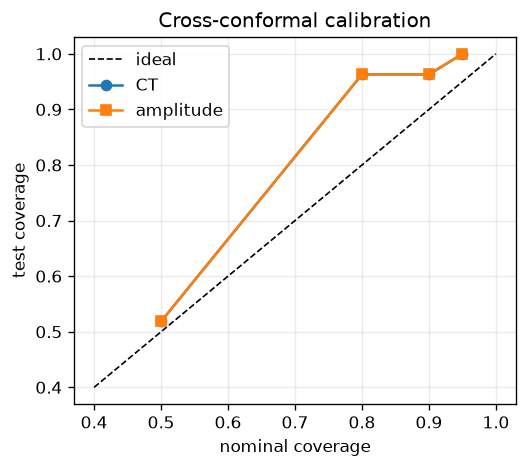

In [11]:
oof_train = oof_on_subset(make_final, tr_idx, splits=5, seed=SEED + 11)
z = np.abs(oof_train - y[tr_idx])
c_scale = 0.2
scale_train = np.abs(oof_train) + c_scale
q90 = np.quantile(z / scale_train, 0.90)

scale_test = np.abs(p_test) + c_scale
lo_ct = p_test - q90 * scale_test
hi_ct = p_test + q90 * scale_test
lo_amp, hi_amp = amp_bounds(lo_ct, hi_ct, te_idx)
true_amp = raw.Amplitude_mm.values[te_idx]

ct_cov = np.mean((y[te_idx] >= lo_ct) & (y[te_idx] <= hi_ct))
amp_cov = np.mean((true_amp >= lo_amp) & (true_amp <= hi_amp))
print(f"conformal scale c       : {c_scale}")
print(f"training q90 multiplier : {q90:.3f}")
print(f"test CT coverage        : {ct_cov:.3f}")
print(f"test amplitude coverage : {amp_cov:.3f}")
print(f"median CT interval width: {np.median(hi_ct - lo_ct):.3f}")
noncross = lo_amp > 0
print("amplitude intervals crossing zero:", int((~noncross).sum()), "/", len(te_idx))
if noncross.any():
    print(f"median amplitude width (non-crossing): {np.median(np.log10(hi_amp[noncross]/lo_amp[noncross])):.3f} decades")

levels = [0.50, 0.80, 0.90, 0.95]
cov_rows = []
for lev in levels:
    q = np.quantile(z / scale_train, lev)
    l = p_test - q * scale_test
    h = p_test + q * scale_test
    la, ha = amp_bounds(l, h, te_idx)
    cov_rows.append({
        "nominal": lev,
        "CT_coverage": np.mean((y[te_idx] >= l) & (y[te_idx] <= h)),
        "amp_coverage": np.mean((true_amp >= la) & (true_amp <= ha)),
        "median_CT_width": np.median(h - l),
    })
cov_table = pd.DataFrame(cov_rows)
display(cov_table.round(3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot([0.4, 1.0], [0.4, 1.0], "k--", lw=1, label="ideal")
ax.plot(cov_table.nominal, cov_table.CT_coverage, "o-", label="CT")
ax.plot(cov_table.nominal, cov_table.amp_coverage, "s-", label="amplitude")
ax.set_xlabel("nominal coverage"); ax.set_ylabel("test coverage")
ax.set_title("Cross-conformal calibration"); ax.legend()
plt.tight_layout(); plt.savefig(ROOT / "fig_v2_calibration.png", dpi=160); plt.show()

## 11. Near-resonance stress test

Only 7 designs are within `|r-1| < 0.15`, and only one of those is in the locked test set. To test the
surrogate honestly at resonance, each near-resonance design is held out in turn and predicted from all
other designs (leave-one-design-out). This is stricter than random CV for these rows.

,id,r,true_CT,pred_CT,true_amp_mm,pred_amp_mm,log10_amp_error
1,150,0.879,-1.334,0.230,3.540,0.611,-0.763
5,209,0.881,0.089,0.122,0.663,0.905,0.135
0,130,0.884,-2.224,0.159,15.781,1.129,-1.145
6,248,0.900,-0.386,-0.296,3.453,2.648,-0.115
3,183,0.914,0.236,0.310,1.162,1.529,0.119
4,198,1.034,0.088,0.080,5.375,4.873,-0.043
2,159,1.122,0.441,0.254,7.956,4.575,-0.240


median |log10 amplitude error|: 0.135 decades
within 2x: 5 / 7
negative-CT near-resonance rows are the hard cases; they are flagged, not hidden.


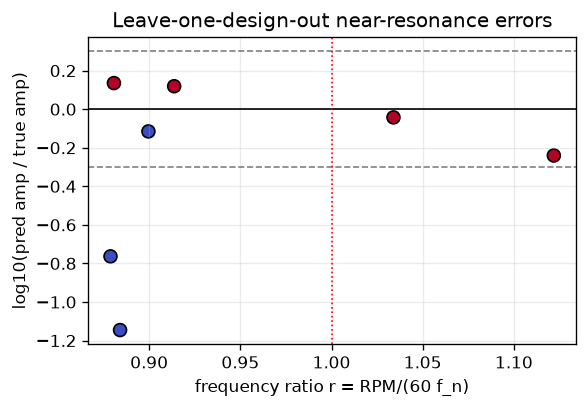

In [12]:
near_idx = np.where(np.abs(raw.r_calc.values - 1.0) < 0.15)[0]
near_rows = []
for i in near_idx:
    tr = np.setdiff1d(np.arange(len(raw)), [i])
    model = make_final().fit(X.iloc[tr], y[tr])
    p = model.predict(X.iloc[[i]])
    pa = amp_from_ct(p, np.array([i]))[0]
    ta = raw.Amplitude_mm.values[i]
    near_rows.append({
        "id": int(ids[i]),
        "r": raw.r_calc.values[i],
        "true_CT": y[i],
        "pred_CT": p[0],
        "true_amp_mm": ta,
        "pred_amp_mm": pa,
        "log10_amp_error": np.log10(max(pa, 1e-12)) - np.log10(ta),
    })
near_table = pd.DataFrame(near_rows).sort_values("r")
display(near_table.round(3))
print("median |log10 amplitude error|:", f"{np.median(np.abs(near_table.log10_amp_error)):.3f} decades")
print("within 2x:", int((np.abs(near_table.log10_amp_error) < np.log10(2)).sum()), "/", len(near_table))
print("negative-CT near-resonance rows are the hard cases; they are flagged, not hidden.")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.axhline(0, color="k", lw=1)
ax.axhline(np.log10(2), color="gray", ls="--", lw=1)
ax.axhline(-np.log10(2), color="gray", ls="--", lw=1)
sc = ax.scatter(near_table.r, near_table.log10_amp_error,
                c=(near_table.true_CT > 0), cmap="coolwarm", vmin=0, vmax=1, s=60, edgecolor="k")
ax.axvline(1.0, color="r", ls=":", lw=1)
ax.set_xlabel("frequency ratio r = RPM/(60 f_n)")
ax.set_ylabel("log10(pred amp / true amp)")
ax.set_title("Leave-one-design-out near-resonance errors")
plt.tight_layout(); plt.savefig(ROOT / "fig_v2_near_resonance.png", dpi=160); plt.show()

## 12. Diagnostics: parity, residuals, and CT

These plots show where the remaining error sits. The resonance location itself is exact; the amplitude
error is driven by the CT correction and the windmill rows.

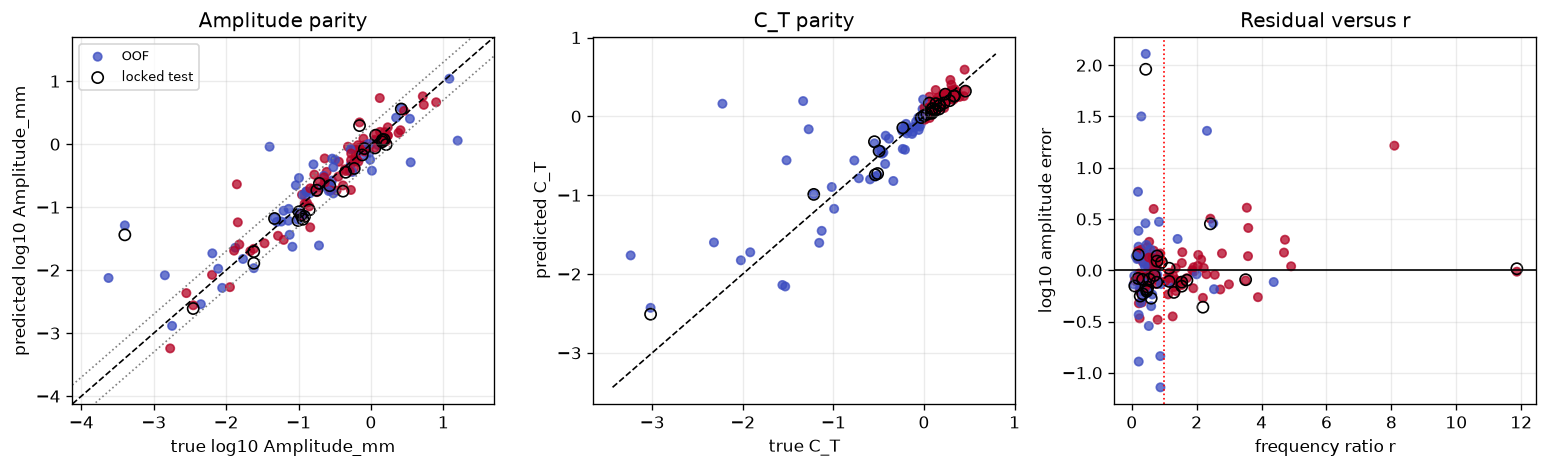

In [13]:
oof_mean = oof_final.mean(axis=0)
amp_oof = amp_from_ct(oof_mean, np.arange(len(raw)))
amp_test = amp_from_ct(p_test, te_idx)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
ax = axes[0]
ax.scatter(raw.log10_amp.values, np.log10(np.maximum(amp_oof, 1e-12)),
           c=(y > 0), cmap="coolwarm", vmin=0, vmax=1, s=25, alpha=0.75, label="OOF")
ax.scatter(raw.log10_amp.values[te_idx], np.log10(np.maximum(amp_test, 1e-12)),
           facecolors="none", edgecolors="k", s=45, label="locked test")
lims = [raw.log10_amp.min()-0.5, raw.log10_amp.max()+0.5]
ax.plot(lims, lims, "k--", lw=1)
for s in (np.log10(2), -np.log10(2)):
    ax.plot(lims, [lims[0]+s, lims[1]+s], color="gray", ls=":", lw=1)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("true log10 Amplitude_mm"); ax.set_ylabel("predicted log10 Amplitude_mm")
ax.set_title("Amplitude parity"); ax.legend(fontsize=8)

ax = axes[1]
ax.scatter(y, oof_mean, c=(y > 0), cmap="coolwarm", vmin=0, vmax=1, s=25, alpha=0.75)
ax.scatter(y[te_idx], p_test, facecolors="none", edgecolors="k", s=45)
lims = [min(y.min(), oof_mean.min())-0.2, max(y.max(), oof_mean.max())+0.2]
ax.plot(lims, lims, "k--", lw=1)
ax.set_xlabel("true C_T"); ax.set_ylabel("predicted C_T")
ax.set_title("C_T parity")

ax = axes[2]
ax.scatter(raw.r_calc.values, np.log10(np.maximum(amp_oof, 1e-12)) - raw.log10_amp.values,
           c=(y > 0), cmap="coolwarm", vmin=0, vmax=1, s=25, alpha=0.75)
ax.scatter(raw.r_calc.values[te_idx], np.log10(np.maximum(amp_test, 1e-12)) - raw.log10_amp.values[te_idx],
           facecolors="none", edgecolors="k", s=45)
ax.axhline(0, color="k", lw=1); ax.axvline(1.0, color="r", ls=":", lw=1)
ax.set_xlabel("frequency ratio r"); ax.set_ylabel("log10 amplitude error")
ax.set_title("Residual versus r")
plt.tight_layout(); plt.savefig(ROOT / "fig_v2_diagnostics.png", dpi=160); plt.show()

## 13. What the CT head learned

Standardized Huber coefficients are shown for the two ensemble members. They are descriptive, not causal:
the features are correlated by construction.

,b13,b13w
CT_BET,0.171,0.169
J_ax,-0.855,-0.860
J_tan,0.138,0.136
tilt,-0.044,-0.045
tw75,0.326,0.329
c_mean,0.031,0.000
solidity,-0.046,0.000
sweep,0.017,0.017
logt,-0.015,-0.014
B,0.053,0.061


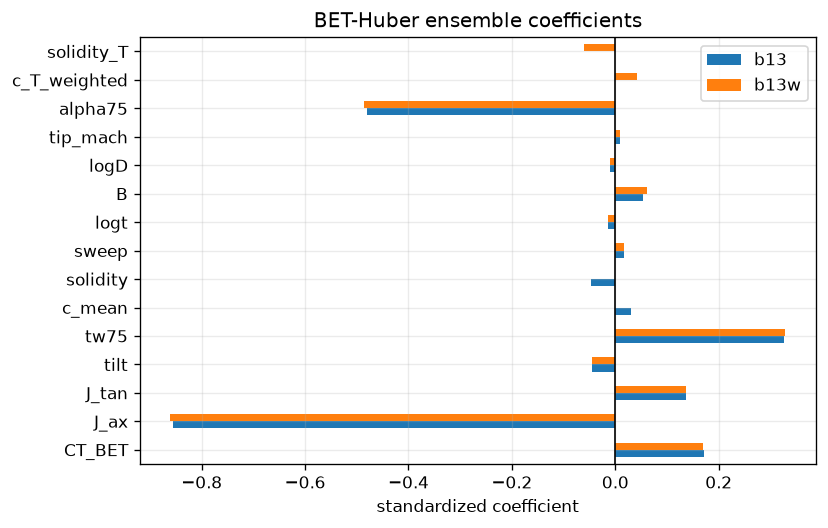

In [14]:
final_full = make_final().fit(X, y)
coefs = []
for name, m in zip(FINAL_COMPONENTS, final_full.ms):
    s = m.coef_series().rename(name)
    coefs.append(s)
coef_table = pd.concat(coefs, axis=1).fillna(0.0)
display(coef_table.round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
coef_table.plot.barh(ax=ax)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("standardized coefficient")
ax.set_title("BET-Huber ensemble coefficients")
plt.tight_layout(); plt.savefig(ROOT / "fig_v2_coefficients.png", dpi=160); plt.show()

## 14. Multivariate domain check

A 1-D min/max check is not enough for a 17-input surrogate. We use a shrinkage Mahalanobis distance and a
5-nearest-neighbour distance on the standardized raw inputs. Points beyond the training 99% Mahalanobis
threshold or the 95th percentile k-NN distance are flagged for engineering review.

In [15]:
raw17 = raw[RAW_INPUTS].values
sc17 = StandardScaler().fit(raw17[tr_idx])
Z = sc17.transform(raw17)
lw = LedoitWolf().fit(Z[tr_idx])
md = lw.mahalanobis(Z)
md_thr = chi2.ppf(0.99, len(RAW_INPUTS))

nn = NearestNeighbors(n_neighbors=5).fit(Z[tr_idx])
kdist, _ = nn.kneighbors(Z)
knn_thr = np.quantile(kdist[tr_idx, -1], 0.95)

domain = raw[["id", "r_calc"]].copy()
domain["mahalanobis"] = md
domain["knn5"] = kdist[:, -1]
domain["MD_flag"] = domain.mahalanobis > md_thr
domain["kNN_flag"] = domain.knn5 > knn_thr

print(f"Mahalanobis 99% threshold : {md_thr:.2f}")
print(f"kNN 95% threshold         : {knn_thr:.2f}")
print("locked-test flags         :",
      int(domain.iloc[te_idx].MD_flag.sum()), "MD,",
      int(domain.iloc[te_idx].kNN_flag.sum()), "kNN")
display(domain.iloc[te_idx].sort_values("mahalanobis", ascending=False).head(8).round(3))

Mahalanobis 99% threshold : 33.41
kNN 95% threshold         : 4.84
locked-test flags         : 0 MD, 1 kNN


,id,r_calc,mahalanobis,knn5,MD_flag,kNN_flag
100,215,1.539,23.189,4.550,False,False
13,115,0.194,21.551,4.731,False,False
83,195,0.094,19.782,4.923,False,True
7,108,0.334,19.666,4.823,False,False
72,183,0.914,18.959,4.721,False,False
12,114,2.422,18.551,4.488,False,False
53,164,0.782,18.411,4.558,False,False
54,165,0.768,17.202,4.355,False,False


## 15. Material and damping envelope

VSPAERO models rigid blades, so the aerodynamic `C_T` does not depend on `E`, `rho`, or structural
damping. The exact FE branch and SDOF magnification do. The table below is therefore a **material/damping
envelope** on top of the same frozen aerodynamic dataset; it is not a new VSPAERO validation.

Only GF-Nylon is present in the dataset. Aluminium, CFRP, and PLA properties are illustrative.

,material,fn_ratio_vs_GF,k_ratio_vs_GF,median_amp_ratio,p05_amp_ratio,p95_amp_ratio
0,GF_Nylon,1.000,1.000,1.000,1.000,1.000
1,Al_6061,1.972,7.667,0.124,0.049,2.755
2,CFRP_QI,2.581,7.778,0.119,0.042,2.920
3,PLA,0.655,0.389,2.704,0.563,12.423


,zeta,median_amp_ratio,p05,p95
0,0.01,1.000,1.000,1.008
1,0.02,1.000,1.000,1.000
2,0.03,1.000,0.987,1.000
3,0.05,0.999,0.949,1.000


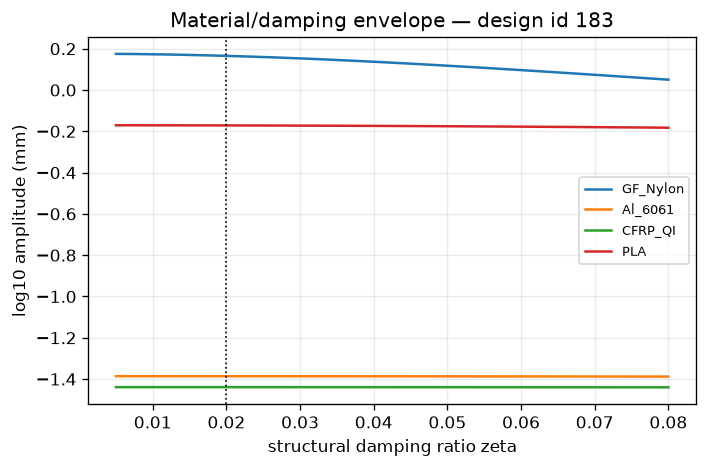

Amplitude is linear in EPS: 0.05/0.10/0.20 scales amplitude by 0.5/1.0/2.0.
The aerodynamic CT head is unchanged by material and zeta.


In [16]:
FN_MAT, K_MAT = {}, {}
for mat_name, mat in MATERIALS.items():
    fn_list, k_list = [], []
    for _, row in raw.iterrows():
        fn, k = blade_fn_and_k(row.Diameter/2.0, [row[f"Chord{i}"] for i in range(1, 6)], row.AirfoilThickness, mat)
        fn_list.append(fn); k_list.append(k)
    FN_MAT[mat_name] = np.asarray(fn_list)
    K_MAT[mat_name] = np.asarray(k_list)

ct_all = final_full.predict(X)
amp_gf = amp_from_ct(ct_all, np.arange(len(raw)), material="GF_Nylon", zeta=0.02)
mat_rows = []
for mat_name, mat in MATERIALS.items():
    amp = amp_from_ct(ct_all, np.arange(len(raw)), material=mat_name, zeta=mat["ZETA"],
                      FN=FN_MAT[mat_name], K=K_MAT[mat_name])
    ratio = amp / np.maximum(amp_gf, 1e-12)
    mat_rows.append({
        "material": mat_name,
        "fn_ratio_vs_GF": np.median(FN_MAT[mat_name] / FN_MAT["GF_Nylon"]),
        "k_ratio_vs_GF": np.median(K_MAT[mat_name] / K_MAT["GF_Nylon"]),
        "median_amp_ratio": np.median(ratio),
        "p05_amp_ratio": np.quantile(ratio, 0.05),
        "p95_amp_ratio": np.quantile(ratio, 0.95),
    })
mat_table = pd.DataFrame(mat_rows)
display(mat_table.round(3))
mat_table.to_csv(ROOT / "material_envelope_v2.csv", index=False)

zeta_rows = []
for zeta in [0.01, 0.02, 0.03, 0.05]:
    amp = amp_from_ct(ct_all, np.arange(len(raw)), material="GF_Nylon", zeta=zeta,
                      FN=FN_MAT["GF_Nylon"], K=K_MAT["GF_Nylon"])
    ratio = amp / np.maximum(amp_gf, 1e-12)
    zeta_rows.append({"zeta": zeta, "median_amp_ratio": np.median(ratio),
                     "p05": np.quantile(ratio, 0.05), "p95": np.quantile(ratio, 0.95)})
zeta_table = pd.DataFrame(zeta_rows)
display(zeta_table.round(3))

# Choose a positive-thrust design near resonance for the damping sweep.
candidates_pos = np.where((y > 0) & (raw.r_calc.values > 0.8) & (raw.r_calc.values < 1.1))[0]
i_sel = int(candidates_pos[0]) if len(candidates_pos) else int(np.where(y > 0)[0][0])
zgrid = np.linspace(0.005, 0.08, 120)

fig, ax = plt.subplots(figsize=(6, 4))
for mat_name, mat in MATERIALS.items():
    amps = []
    for zeta in zgrid:
        amps.append(amp_from_ct(np.array([ct_all[i_sel]]), np.array([i_sel]), material=mat_name, zeta=zeta,
                                FN=FN_MAT[mat_name][[i_sel]], K=K_MAT[mat_name][[i_sel]])[0])
    ax.plot(zgrid, np.log10(np.maximum(amps, 1e-12)), label=mat_name)
ax.axvline(0.02, color="k", ls=":", lw=1)
ax.set_xlabel("structural damping ratio zeta")
ax.set_ylabel("log10 amplitude (mm)")
ax.set_title(f"Material/damping envelope — design id {int(ids[i_sel])}")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(ROOT / "fig_v2_material_damping.png", dpi=160); plt.show()

print("Amplitude is linear in EPS: 0.05/0.10/0.20 scales amplitude by 0.5/1.0/2.0.")
print("The aerodynamic CT head is unchanged by material and zeta.")

## 16. RPM sweep centered on the exact resonance

The old notebook swept a fixed 500–5000 RPM range. Here the sweep is centered on `60 f_n` for the chosen
design. The CT model is evaluated off-design, so this is a design-study extrapolation, not a new
validation point. The resonance location and the SDOF magnification shape are exact.

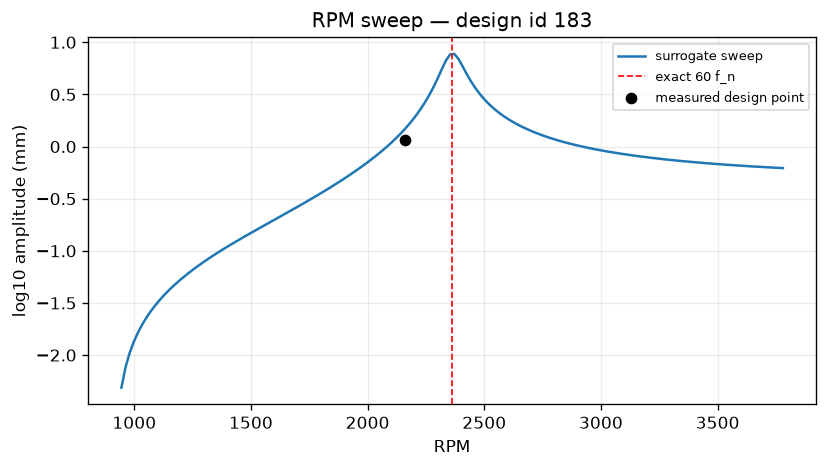

design id 183: f_n = 39.38 Hz, resonance RPM = 2362.5, measured RPM = 2158.6
CT model input J range over sweep: 0.322 to 1.290; training J_ax range: 0.006 to 5.596


In [17]:
fn0 = raw.fn_calc.values[i_sel]
rpm_res = 60.0 * fn0
rpms = np.linspace(max(100.0, 0.4 * rpm_res), 1.6 * rpm_res, 160)

sweep = pd.concat([raw.iloc[[i_sel]].copy()] * len(rpms), ignore_index=True)
sweep["RPM"] = rpms
Xs = engineer(sweep)
ct_sweep = final_full.predict(Xs)

n_s = rpms / 60.0
r_s = n_s / fn0
mf_s = magnification(r_s, ZETA_DEFAULT)
amp_s = 1e3 * (EPS * np.abs(ct_sweep) * RHO_AIR * n_s**2 * raw.Diameter.values[i_sel]**4 / raw.Blades.values[i_sel]) / raw.k_calc.values[i_sel] * mf_s

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rpms, np.log10(np.maximum(amp_s, 1e-12)), label="surrogate sweep")
ax.axvline(rpm_res, color="r", ls="--", lw=1, label="exact 60 f_n")
ax.scatter([raw.RPM.values[i_sel]], [raw.log10_amp.values[i_sel]], color="k", zorder=5, label="measured design point")
ax.set_xlabel("RPM"); ax.set_ylabel("log10 amplitude (mm)")
ax.set_title(f"RPM sweep — design id {int(ids[i_sel])}")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(ROOT / "fig_v2_rpm_sweep.png", dpi=160); plt.show()

print(f"design id {int(ids[i_sel])}: f_n = {fn0:.2f} Hz, resonance RPM = {rpm_res:.1f}, measured RPM = {raw.RPM.values[i_sel]:.1f}")
print(f"CT model input J range over sweep: {Xs.J_ax.min():.3f} to {Xs.J_ax.max():.3f}; training J_ax range: {X.J_ax.min():.3f} to {X.J_ax.max():.3f}")

## 17. Forensic check: are `RotorDia`, `Rx`, and `Rz` updated per case?

Baseline `propellerai_baseline.vsp3` contains:

* `RotorDia = 0.17 m`
* `Rx = -0.81925`, `Rz = 0.57343` (the 34.99° baseline tilt)

`prop-loop.vspscript` updates `Diameter` and `Y_Rel_Rotation` on `PropGeom`, and updates `RPM` on the
unsteady group. It does **not** explicitly write `RotorDia`, `Rx`, or `Rz` inside `<UnsteadyGroup>`.

The check below scans generated `Results/results_*/prop_setup_*.vsp3` files if they exist. If they do not,
the audit is blocked; the only `.vsp3` currently in the project is the baseline. Generate one case and
re-run this cell to resolve whether `Update()` propagated the values.

In [18]:
def parse_unsteady(path):
    text = Path(path).read_text(errors="ignore")
    m = re.search(r"<UnsteadyGroup>(.*?)</UnsteadyGroup>", text, re.S)
    if not m:
        return None
    body = m.group(1)
    vals = {}
    for tag in ["RotorDia", "Rx", "Ry", "Rz", "RPM"]:
        mm = re.search(rf"<{tag} Value=\"([^\"]+)\"", body)
        vals[tag] = float(mm.group(1)) if mm else np.nan
    return vals

base_path = ROOT / "propellerai_baseline.vsp3"
base_vals = parse_unsteady(base_path) if base_path.exists() else None
print("baseline UnsteadyGroup:", base_vals)

base_tilt = 34.99
if base_vals:
    print("expected from baseline tilt:",
          {"Rx": -np.cos(np.deg2rad(base_tilt)), "Rz": np.sin(np.deg2rad(base_tilt)), "RotorDia": 0.17})
    print("baseline match:",
          {"Rx": np.isclose(base_vals["Rx"], -np.cos(np.deg2rad(base_tilt))),
           "Rz": np.isclose(base_vals["Rz"], np.sin(np.deg2rad(base_tilt))),
           "RotorDia": np.isclose(base_vals["RotorDia"], 0.17)})

vsp_files = sorted(ROOT.glob("Results/results_*/prop_setup_*.vsp3"))
print(f"\ngenerated per-case .vsp3 files found: {len(vsp_files)}")
if not vsp_files:
    print("BLOCKED: no Results/ directory or generated prop_setup_*.vsp3 is present.")
    print("The forensic update check cannot be completed from the current project snapshot.")
else:
    rows = []
    for f in vsp_files:
        mm = re.search(r"prop_setup_(\d+)", f.name)
        if not mm:
            continue
        case_id = int(mm.group(1))
        vals = parse_unsteady(f)
        if vals is None or case_id not in set(raw.id):
            continue
        row = raw.loc[raw.id == case_id].iloc[0]
        expected = {
            "Rx": -np.cos(np.deg2rad(row.Tilt)),
            "Rz": np.sin(np.deg2rad(row.Tilt)),
            "RotorDia": row.Diameter,
        }
        rows.append({
            "id": case_id,
            "tilt": row.Tilt,
            "diameter": row.Diameter,
            "Rx_file": vals["Rx"], "Rx_expected": expected["Rx"],
            "Rz_file": vals["Rz"], "Rz_expected": expected["Rz"],
            "RotorDia_file": vals["RotorDia"], "RotorDia_expected": expected["RotorDia"],
            "Rx_ok": np.isclose(vals["Rx"], expected["Rx"], atol=1e-4),
            "Rz_ok": np.isclose(vals["Rz"], expected["Rz"], atol=1e-4),
            "RotorDia_ok": np.isclose(vals["RotorDia"], expected["RotorDia"], atol=1e-4),
        })
    if rows:
        display(pd.DataFrame(rows).round(4))
    else:
        print("Files found, but none matched a retained dataset row.")

baseline UnsteadyGroup: {'RotorDia': 0.17, 'Rx': -0.8192521397853463, 'Ry': 0.0, 'Rz': 0.5734334586132305, 'RPM': 2645.02}
expected from baseline tilt: {'Rx': np.float64(-0.8192521397853463), 'Rz': np.float64(0.5734334586132305), 'RotorDia': 0.17}
baseline match: {'Rx': np.True_, 'Rz': np.True_, 'RotorDia': np.True_}

generated per-case .vsp3 files found: 0
BLOCKED: no Results/ directory or generated prop_setup_*.vsp3 is present.
The forensic update check cannot be completed from the current project snapshot.


## 18. Confidence tiers and what remains unvalidated

**Tier 1 — exact (`R^2 = 1.000` by construction):**
`f_n`, `k_tip`, `r = RPM/(60 f_n)`, and the SDOF magnification shape. The embedded FE branch reproduces
the dataset values to float round-off.

**Tier 2 — high-reliability decision support:**
resonance-risk classification and amplitude ranking. The locked test gives ROC-AUC around 0.96 and
Spearman around 0.95 for the BET-Huber ensemble.

**Tier 3 — calibrated amplitude estimate:**
the 90% cross-conformal interval is honest but wide. Propeller mode is the validated absolute-amplitude
regime. Windmill mode, especially near resonance, remains the weak spot (`id 130` and `id 150` in the
leave-one-out stress test are examples).

**Unresolved without new data or files:**

1. The `UnsteadyGroup` forensic check needs at least one generated `prop_setup_*.vsp3`.
2. The per-case VSPAERO CSV time histories are absent, so the exact aggregation/time-averaging of
   `Force [N]` cannot be audited.
3. A full amplitude-vs-RPM curve for a fixed blade cannot be empirically validated from a single-RPM
   dataset. The surrogate's resonance shape is physics, not a learned curve.
4. Material and damping envelopes are analytical; only GF-Nylon is in the frozen dataset.

## 19. Save artifacts and summary

The final model is refit on all 133 retained rows after the locked-test evaluation. The saved JSON contains
the exact feature lists, scalers, Huber coefficients, conformal multiplier, and metrics needed to rebuild
the predictor without relying on notebook pickle state.

In [19]:
# Refit on all retained rows for deployment-style artifacts
final_all = make_final().fit(X, y)
pos_model = HuberCT(FEAT["b8"]).fit(X.loc[y > 0], y[y > 0])

summary = pd.DataFrame([
    {"tier": "exact", "item": "f_n max relative error", "value": float(np.max(np.abs(raw.fn_calc / raw.fn_Hz - 1)))},
    {"tier": "exact", "item": "k_tip max relative error", "value": float(np.max(np.abs(raw.k_calc / k_data - 1)))},
    {"tier": "ranking", "item": "locked-test risk AUC", "value": float(m_test["risk_AUC"])},
    {"tier": "ranking", "item": "locked-test Spearman", "value": float(m_test["spearman"])},
    {"tier": "amplitude", "item": "locked-test amp R2", "value": float(m_test["amp_R2"])},
    {"tier": "amplitude", "item": "locked-test within 2x", "value": float(m_test["within2x"])},
    {"tier": "calibration", "item": "90% CT coverage", "value": float(ct_cov)},
    {"tier": "calibration", "item": "90% amplitude coverage", "value": float(amp_cov)},
])
summary_display = summary.copy()
summary_display["value"] = summary_display["value"].map(lambda v: f"{v:.3e}" if abs(v) < 1e-3 else f"{v:.4f}")
display(summary_display)
summary.to_csv(ROOT / "summary_v2.csv", index=False)

def _json_default(o):
    if isinstance(o, (np.floating, np.integer)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)

model_json = {
    "final_components": list(FINAL_COMPONENTS),
    "feature_sets": FEAT,
    "huber_components": {
        name: {
            "features": m.cols,
            "mean": m.sc.mean_.tolist(),
            "scale": m.sc.scale_.tolist(),
            "coef": m.m.coef_.tolist(),
            "intercept": float(m.m.intercept_),
            "alpha": float(m.alpha),
            "epsilon": float(m.epsilon),
        }
        for name, m in zip(FINAL_COMPONENTS, final_all.ms)
    },
    "conformal": {"scale_c": float(c_scale), "q90": float(q90), "level": 0.90},
    "materials": MATERIALS,
    "metrics": {
        "locked_test": {k: float(v) for k, v in m_test.items()},
        "cv_ensemble": cv_table.loc[cv_table.model == "Ensemble b13+b13w"].iloc[0].to_dict(),
    },
}
with open(ROOT / "model_v2.json", "w") as f:
    json.dump(model_json, f, indent=2, default=_json_default)

with open(ROOT / "models_v2.pkl", "wb") as f:
    pickle.dump({"final_all": final_all, "positive_only": pos_model, "q90": q90, "c_scale": c_scale}, f)

print("saved model_v2.json, models_v2.pkl, summary_v2.csv")
print("Final locked-test amplitude R2:", f"{m_test['amp_R2']:.3f}",
      "| within 2x:", f"{m_test['within2x']:.3f}",
      "| risk AUC:", f"{m_test['risk_AUC']:.3f}")
print("Primary use: propeller-mode absolute amplitude + resonance-risk ranking.")
print("Windmill-mode absolute amplitude is explicitly lower-confidence.")

,tier,item,value
0,exact,f_n max relative error,1.027e-06
1,exact,k_tip max relative error,1.038e-08
2,ranking,locked-test risk AUC,0.9571
3,ranking,locked-test Spearman,0.9512
4,amplitude,locked-test amp R2,0.7618
5,amplitude,locked-test within 2x,0.8889
6,calibration,90% CT coverage,0.9630
7,calibration,90% amplitude coverage,0.9630


saved model_v2.json, models_v2.pkl, summary_v2.csv
Final locked-test amplitude R2: 0.762 | within 2x: 0.889 | risk AUC: 0.957
Primary use: propeller-mode absolute amplitude + resonance-risk ranking.
Windmill-mode absolute amplitude is explicitly lower-confidence.


## Executive summary

The v2 surrogate keeps the physically meaningful split:

1. exact FE structural branch (`f_n`, `k_tip`, `r`, `MF`);
2. one learned aerodynamic head, a BET-informed robust `C_T` ensemble;
3. exact SDOF amplitude combination;
4. cross-conformal uncertainty and explicit regime reporting.

The learned CT head is no longer asked to infer structural dynamics or to fit a 17-D black box. The CT
metrics improve from the original GP's approximately `R^2 = 0.65` to about `0.73` in repeated CV, and the
amplitude metrics improve from about `0.59` to about `0.79` in repeated CV. The locked test is stronger,
but only 27 rows; the near-resonance stress test and the windmill rows are the honest caveats.

The remaining blockers are data/file availability, not ML hyperparameters: generated per-case `.vsp3`
files for the `UnsteadyGroup` forensic check, and VSPAERO time histories for force aggregation.